In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import json
import math
from matplotlib.pyplot import cm

plt.style.use('seaborn-v0_8') # I personally prefer seaborn for the graph style, but you may choose whichever you want.
params = {"ytick.color" : "black",
          "xtick.color" : "black",
          "axes.labelcolor" : "black",
          "axes.edgecolor" : "black",
          "text.usetex" : True,
          "font.family" : "serif",
          "font.serif" : ["Computer Modern Serif"]}
plt.rcParams.update(params)

output_dir = "/Users/russell/projects/stencil_research/cpu_attention_suite/plots"

In [9]:
results_dirs = [
    "/Users/russell/projects/stencil_research/cpu_attention_suite/results/par_sweep",
]

plot_data = {}
for n in ["fa2", "rec"]:
    plot_data[n] = {}

def load_results_file(path):
    with open(json_path, 'r') as json_file:
        data = json.load(json_file)
        threads = data["threads"]
        name = data["name"]
        time = np.average(data["times"]) / 1000.0
        plot_data[name][threads] = time;
        
for results_dir in results_dirs:  
    for file in sorted(os.listdir(results_dir)):
        json_path = f"{results_dir}/{file}"
        load_results_file(json_path)

threads = sorted(plot_data["fa2"].keys())
fa2_times = [plot_data["fa2"][thread] for thread in threads]
rec_times = [plot_data["rec"][thread] for thread in threads]

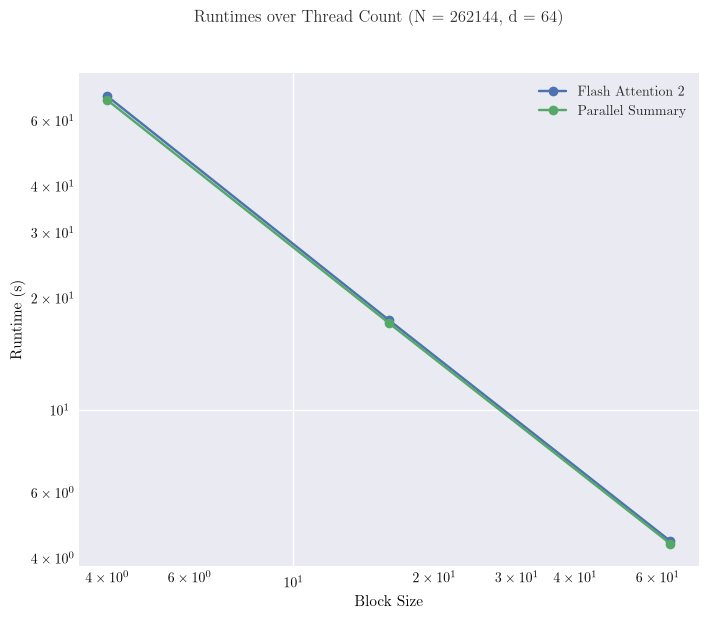

In [10]:
width = 8
height_ratio = 0.8
fig = plt.figure(figsize=(width, width * height_ratio))
n_rows = 1
n_cols = 1
width_ratios = [1.0]
height_ratios = [1.0]
gs1 = fig.add_gridspec(
    n_rows, n_cols,
    width_ratios = width_ratios, 
    height_ratios = height_ratios,
    wspace = 0.45,
    hspace = 0.45,
)
ax_1 = fig.add_subplot(gs1[0, 0])


ax_1.plot(
    threads, 
    fa2_times,
    label="Flash Attention 2",
    marker='o',
)
ax_1.plot(
    threads, 
    rec_times,
    label="Parallel Summary",
    marker='o',
)
    
ax_1.set_xticks(threads)
ax_1.set_ylabel("Runtime (s)")
ax_1.set_xlabel("Block Size")
ax_1.legend()
ax_1.set_xscale('log')
ax_1.set_yscale('log')


fig.suptitle("Runtimes over Thread Count (N = 262144, d = 64)")
plt.savefig(f"{output_dir}/par_sweep.pdf")